In [1]:
from datetime import datetime
import requests
import pandas as pd
import numpy as np
import time

In [2]:

# --- HÀM TẢI DỮ LIỆU TỪ BINANCE ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        response = requests.get(general_url, params=params)
        if response.status_code != 200:
            print("Error:", response.status_code, response.text)
            break

        data = response.json()
        if not data:
            break
        all_klines.extend(data)

        last_ts = data[-1][0]
        start_time = last_ts + 1
        time.sleep(0.3)

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "o", "l", "h", "c", "v",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])

    df = df[["timestamp", "o", "c", "h", "l", "v"]]
    df.columns = ["timestamp", "Open", "High", "Low", "Close", "Volume"]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

In [3]:
# --- NHẬP THỜI GIAN ---
symbol = "BTCUSDT"
interval = "1h"
start_date = "1/1/2017"
end_date = "21/12/2025"

print("\U0001F4E5 Đang tải dữ liệu từ Binance...")
df_all = fetch_binance_kline_df(symbol, interval, start_date, end_date)
# print(df_all)
print(f"✅ Dữ liệu đã tải: {len(df_all)} dòng, từ {start_date} đến {end_date}")

📥 Đang tải dữ liệu từ Binance...
Error: 451 {
  "code": 0,
  "msg": "Service unavailable from a restricted location according to 'b. Eligibility' in https://www.binance.com/en/terms. Please contact customer service if you believe you received this message in error."
}
✅ Dữ liệu đã tải: 0 dòng, từ 1/1/2017 đến 21/12/2025


In [4]:
df_all

,Open,High,Low,Close,Volume
timestamp,,,,,


In [5]:
from datetime import datetime
import requests
import pandas as pd
import time

# --- HÀM TẢI DỮ LIỆU TỪ BINANCE ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    # Thêm giờ cuối ngày để lấy trọn vẹn dữ liệu ngày cuối
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"--> Bắt đầu tải {symbol} từ {start_str} đến {end_str}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }

        try:
            response = requests.get(general_url, params=params, timeout=10) # Thêm timeout
            if response.status_code != 200:
                print(f"Lỗi API: {response.status_code} - {response.text}")
                break

            data = response.json()
            if not data:
                break

            all_klines.extend(data)

            # Cập nhật thời gian bắt đầu cho vòng lặp tiếp theo
            last_ts = data[-1][0]
            start_time = last_ts + 1

            # In tiến trình tải để biết code không bị treo
            print(f"Đã tải đến: {datetime.fromtimestamp(last_ts/1000).strftime('%d/%m/%Y %H:%M')}", end='\r')

            time.sleep(0.1) # Giảm sleep xuống 0.1 để nhanh hơn (Binance cho phép 1200 req/phút)

        except Exception as e:
            print(f"Lỗi kết nối: {e}")
            time.sleep(5)
            continue

    if not all_klines:
        print("\nKhông tìm thấy dữ liệu nào!")
        return pd.DataFrame()

    print("\nĐang xử lý dữ liệu...")

    # --- SỬA LỖI QUAN TRỌNG: ĐẶT TÊN CỘT ĐÚNG THỨ TỰ API BINANCE ---
    # Thứ tự gốc của Binance: [Open Time, Open, High, Low, Close, Volume, ...]
    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])

    # Chỉ lấy các cột cần thiết
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]

    # Chuyển đổi kiểu dữ liệu
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)

    # Chuyển string sang float
    cols = ["Open", "High", "Low", "Close", "Volume"]
    df[cols] = df[cols].astype(float)

    return df

# --- NHẬP THỜI GIAN ---
symbol = "BTCUSDT"
interval = "1h"
start_date = "1/1/2017"
end_date = "21/12/2025"

print("📥 Đang khởi tạo...")
df_all = fetch_binance_kline_df(symbol, interval, start_date, end_date)

if not df_all.empty:
    print(f"✅ Dữ liệu đã tải thành công: {len(df_all)} dòng.")
    print(df_all.head())
    print(df_all.tail())
    # Lưu file nếu cần
    # df_all.to_csv(f"{symbol}_{interval}_data.csv")
else:
    print("❌ Tải thất bại hoặc không có dữ liệu.")

📥 Đang khởi tạo...
--> Bắt đầu tải BTCUSDT từ 1/1/2017 đến 21/12/2025...
Lỗi API: 451 - {
  "code": 0,
  "msg": "Service unavailable from a restricted location according to 'b. Eligibility' in https://www.binance.com/en/terms. Please contact customer service if you believe you received this message in error."
}

Không tìm thấy dữ liệu nào!
❌ Tải thất bại hoặc không có dữ liệu.


#### Strat 1

===== METRICS =====
   Total Return: 1.4166
   Max Drawdown: -0.0554
         Sharpe: 2.6790
         Trades: 110
        Winrate: 0.6455
  Avg PnL/Trade: 128.7816
  Profit Factor: 3.0846
   Final Equity: 24165.9783

===== TRADES (head) =====


,entry_time,exit_time,side,entry,exit,qty,pnl,pnl_gross,fee,bars_held,reason
0,2023-10-23 03:00:00,2023-10-23 09:00:00,long,30607.275033,30356.169261,0.398239,-109.711198,-100.000000,9.711198,5,SL
1,2023-10-23 22:00:00,2023-10-23 23:00:00,long,31824.745121,32853.737051,0.251983,252.769242,259.288391,6.519149,0,TP
2,2023-10-24 00:00:00,2023-10-24 01:00:00,long,32445.205975,33812.551422,0.187448,251.338057,256.306008,4.967951,0,TP
3,2023-11-01 20:00:00,2023-11-02 13:00:00,long,35270.905560,34968.666555,0.343913,-113.606485,-103.943961,9.662524,16,SL
4,2023-11-07 20:00:00,2023-11-07 22:00:00,long,35596.587209,35262.824972,0.308027,-111.538551,-102.807896,8.730655,1,SL
5,2023-11-09 04:00:00,2023-11-09 14:00:00,long,36444.120486,37388.213788,0.290519,265.697435,274.277322,8.579887,9,TP
6,2023-11-15 18:00:00,2023-11-16 12:00:00,long,37032.138349,37319.990000,0.254752,65.754329,73.330880,7.576551,18,TimeExit
7,2023-11-19 23:00:00,2023-11-20 03:00:00,long,37333.701285,37096.248825,0.442223,-118.172894,-105.007028,13.165866,3,SL
8,2023-11-28 17:00:00,2023-11-29 11:00:00,long,37914.817924,38159.010000,0.333977,71.391697,81.554449,10.162753,18,TimeExit
9,2023-12-04 02:00:00,2023-12-04 05:00:00,long,40650.471352,41477.312021,0.340656,270.477068,281.667987,11.190919,2,TP


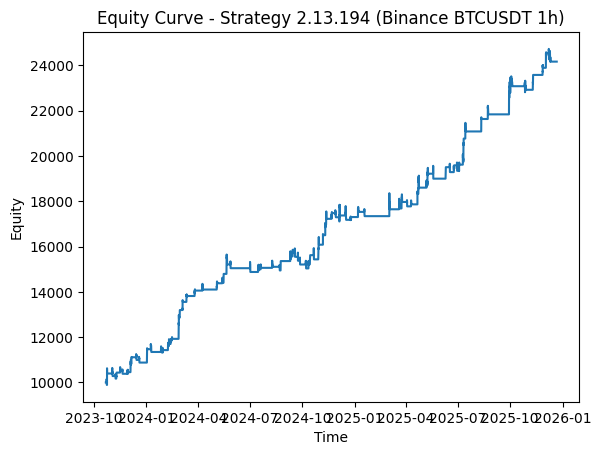

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# Indicators
# =========================
def true_range(df: pd.DataFrame) -> pd.Series:
    high = df["High"]
    low  = df["Low"]
    close_prev = df["Close"].shift(1)
    tr = pd.concat([
        (high - low),
        (high - close_prev).abs(),
        (low  - close_prev).abs()
    ], axis=1).max(axis=1)
    return tr

def atr_wilder(df: pd.DataFrame, period: int) -> pd.Series:
    """Wilder ATR (RMA). JForex ATR gần với kiểu này hơn SMA."""
    tr = true_range(df)
    atr = tr.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
    return atr

# =========================
# Backtest (Strategy 2.13.194 logic)
# =========================
def backtest_strategy_2_13_194(
    df: pd.DataFrame,
    initial_equity: float = 10_000.0,
    risk_percent: float = 0.01,      # 1% balance per trade
    max_qty: float | None = None,    # giống mmMaxLots (nếu bạn muốn giới hạn)
    fee_rate: float = 0.0004,        # ví dụ 0.04% mỗi side (tùy bạn chỉnh)
    slippage_bps: float = 0.0,       # slippage theo bps (0.0 = không)
    verbose: bool = False
):
    df = df.copy()

    # --- Params y như logic đã mô tả ---
    ATRRisingPeriod = 30
    PeriodParam = 20
    ATRPeriod = 20
    PriceEntryMult = 2.4
    StopLossCoef = 1.6
    ProfitTargetCoef = 4.4
    ProfitATRPeriod = 25
    PendingExpireBars = 8
    ExitAfterBars = 18

    # --- Indicators ---
    df["ATR20"] = atr_wilder(df, 20)
    df["ATR25"] = atr_wilder(df, 25)
    df["ATR30"] = atr_wilder(df, 30)

    # Highest/Lowest of CLOSE over 20 bars, then shift(2)
    df["HH_close_20_s2"] = df["Close"].rolling(PeriodParam).max().shift(2)
    df["LL_close_20_s2"] = df["Close"].rolling(PeriodParam).min().shift(2)

    # For signals: ATR30[t-2] > ATR30[t-3]
    # (t-2 == shift(2), t-3 == shift(3))
    df["atr30_s2"] = df["ATR30"].shift(2)
    df["atr30_s3"] = df["ATR30"].shift(3)

    # Entry buffer uses ATR20 shift(3)
    df["atr20_s3"] = df["ATR20"].shift(3)

    # SL/PT distances use ATR20 shift(1), ATR25 shift(1)
    df["atr20_s1"] = df["ATR20"].shift(1)
    df["atr25_s1"] = df["ATR25"].shift(1)

    # --- Simulation state ---
    equity = initial_equity
    equity_curve = []
    equity_index = []

    pending = None  # dict: {side, entry, sl_dist, tp_dist, placed_i}
    pos = None      # dict: {side, entry, qty, sl, tp, entry_i, bars_held}

    trades = []     # store trade logs

    def apply_fees(notional: float) -> float:
        return fee_rate * notional

    def slip_price(price: float, is_buy: bool) -> float:
        # bps -> fraction
        slip = (slippage_bps / 10_000.0)
        return price * (1 + slip) if is_buy else price * (1 - slip)

    # Start index after indicators are valid
    start_i = max(PeriodParam + 5, 50)

    for i in range(start_i, len(df)):
        row = df.iloc[i]
        ts = df.index[i]

        o, h, l, c = row["Open"], row["High"], row["Low"], row["Close"]

        # 1) Pending expiration
        if pending is not None:
            if i - pending["placed_i"] >= PendingExpireBars:
                if verbose:
                    print(ts, "Pending expired")
                pending = None

        # 2) If in position: check SL/TP intrabar, else time-exit
        if pos is not None:
            side = pos["side"]
            entry = pos["entry"]
            qty = pos["qty"]
            sl = pos["sl"]
            tp = pos["tp"]

            exit_reason = None
            exit_price = None

            if side == "long":
                hit_sl = (l <= sl)
                hit_tp = (h >= tp)
                if hit_sl and hit_tp:
                    # Conservative: SL first
                    exit_reason = "SL&TP_same_bar -> SL"
                    exit_price = sl
                elif hit_sl:
                    exit_reason = "SL"
                    exit_price = sl
                elif hit_tp:
                    exit_reason = "TP"
                    exit_price = tp
            else:  # short (hầu như không xảy ra theo rule gốc)
                hit_sl = (h >= sl)
                hit_tp = (l <= tp)
                if hit_sl and hit_tp:
                    exit_reason = "SL&TP_same_bar -> SL"
                    exit_price = sl
                elif hit_sl:
                    exit_reason = "SL"
                    exit_price = sl
                elif hit_tp:
                    exit_reason = "TP"
                    exit_price = tp

            # Time exit if not exited by SL/TP
            if exit_reason is None:
                pos["bars_held"] += 1
                if pos["bars_held"] >= ExitAfterBars:
                    exit_reason = "TimeExit"
                    exit_price = c  # close of bar

            if exit_reason is not None:
                # apply slippage
                if side == "long":
                    exit_price_eff = slip_price(exit_price, is_buy=False)
                    pnl = qty * (exit_price_eff - entry)
                    fee = apply_fees(entry * qty) + apply_fees(exit_price_eff * qty)
                else:
                    exit_price_eff = slip_price(exit_price, is_buy=True)
                    pnl = qty * (entry - exit_price_eff)
                    fee = apply_fees(entry * qty) + apply_fees(exit_price_eff * qty)

                equity += (pnl - fee)

                trades.append({
                    "entry_time": pos["entry_time"],
                    "exit_time": ts,
                    "side": side,
                    "entry": entry,
                    "exit": exit_price_eff,
                    "qty": qty,
                    "pnl": pnl - fee,
                    "pnl_gross": pnl,
                    "fee": fee,
                    "bars_held": pos["bars_held"],
                    "reason": exit_reason
                })

                pos = None

        # 3) If not in position, check pending fill
        if pos is None and pending is not None:
            if pending["side"] == "long":
                if h >= pending["entry"]:
                    fill = slip_price(pending["entry"], is_buy=True)

                    # position sizing by risk% with SL distance
                    sl_dist = pending["sl_dist"]
                    risk_amount = equity * risk_percent
                    qty = risk_amount / sl_dist if sl_dist > 0 else 0.0
                    if max_qty is not None:
                        qty = min(qty, max_qty)

                    if qty > 0:
                        sl = fill - sl_dist
                        tp = fill + pending["tp_dist"]

                        pos = {
                            "side": "long",
                            "entry": fill,
                            "qty": qty,
                            "sl": sl,
                            "tp": tp,
                            "entry_i": i,
                            "entry_time": ts,
                            "bars_held": 0
                        }

                    pending = None

            else:  # short (theo logic gốc gần như không mở)
                if l <= pending["entry"]:
                    fill = slip_price(pending["entry"], is_buy=False)

                    sl_dist = pending["sl_dist"]
                    risk_amount = equity * risk_percent
                    qty = risk_amount / sl_dist if sl_dist > 0 else 0.0
                    if max_qty is not None:
                        qty = min(qty, max_qty)

                    if qty > 0:
                        sl = fill + sl_dist
                        tp = fill - pending["tp_dist"]

                        pos = {
                            "side": "short",
                            "entry": fill,
                            "qty": qty,
                            "sl": sl,
                            "tp": tp,
                            "entry_i": i,
                            "entry_time": ts,
                            "bars_held": 0
                        }

                    pending = None

        # 4) If flat and no pending: evaluate signals and place pending order
        if pos is None and pending is None:
            # Signals: ATR30[t-2] > ATR30[t-3]
            atr30_s2 = row["atr30_s2"]
            atr30_s3 = row["atr30_s3"]
            long_signal = (pd.notna(atr30_s2) and pd.notna(atr30_s3) and (atr30_s2 > atr30_s3))
            short_signal = long_signal  # y như code gốc

            # Entry levels
            hh = row["HH_close_20_s2"]
            ll = row["LL_close_20_s2"]
            atr20_s3 = row["atr20_s3"]

            # SL/PT distances at placement time
            atr20_s1 = row["atr20_s1"]
            atr25_s1 = row["atr25_s1"]

            if all(pd.notna(x) for x in [hh, ll, atr20_s3, atr20_s1, atr25_s1]):

                if long_signal:
                    entry = hh + PriceEntryMult * atr20_s3
                    sl_dist = StopLossCoef * atr20_s1
                    tp_dist = ProfitTargetCoef * atr25_s1

                    if sl_dist > 0 and tp_dist > 0:
                        pending = {
                            "side": "long",
                            "entry": entry,
                            "sl_dist": sl_dist,
                            "tp_dist": tp_dist,
                            "placed_i": i
                        }

                elif short_signal and (not long_signal):
                    entry = ll - PriceEntryMult * atr20_s3
                    sl_dist = StopLossCoef * atr20_s1
                    tp_dist = ProfitTargetCoef * atr25_s1

                    if sl_dist > 0 and tp_dist > 0:
                        pending = {
                            "side": "short",
                            "entry": entry,
                            "sl_dist": sl_dist,
                            "tp_dist": tp_dist,
                            "placed_i": i
                        }

        # 5) Mark-to-market equity curve
        # Nếu đang giữ position, mark-to-market theo Close
        if pos is None:
            eq_mark = equity
        else:
            if pos["side"] == "long":
                eq_mark = equity + pos["qty"] * (c - pos["entry"])
            else:
                eq_mark = equity + pos["qty"] * (pos["entry"] - c)

        equity_curve.append(eq_mark)
        equity_index.append(ts)

    equity_curve = pd.Series(equity_curve, index=pd.DatetimeIndex(equity_index), name="equity")
    trades_df = pd.DataFrame(trades)

    return equity_curve, trades_df


# =========================
# Metrics
# =========================
def performance_metrics(equity: pd.Series, trades: pd.DataFrame, bars_per_year: int = 365*24):
    rets = equity.pct_change().dropna()

    total_return = equity.iloc[-1] / equity.iloc[0] - 1

    # Max drawdown
    peak = equity.cummax()
    dd = equity / peak - 1
    max_dd = dd.min()

    # Sharpe (assume risk-free = 0)
    if rets.std() > 0:
        sharpe = (rets.mean() / rets.std()) * np.sqrt(bars_per_year)
    else:
        sharpe = np.nan

    n_trades = len(trades)
    winrate = (trades["pnl"] > 0).mean() if n_trades > 0 else np.nan
    avg_pnl = trades["pnl"].mean() if n_trades > 0 else np.nan
    profit_factor = (trades.loc[trades["pnl"] > 0, "pnl"].sum() /
                     (-trades.loc[trades["pnl"] < 0, "pnl"].sum())
                    ) if (n_trades > 0 and (trades["pnl"] < 0).any()) else np.nan

    return {
        "Total Return": total_return,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": n_trades,
        "Winrate": winrate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "Final Equity": equity.iloc[-1]
    }


# =========================
# RUN (df_all là dataframe bạn đã tải)
# =========================
equity_curve, trades_df = backtest_strategy_2_13_194(
    df_all,
    initial_equity=10_000,
    risk_percent=0.01,
    max_qty=None,        # hoặc set 1.0 nếu bạn muốn giống mmMaxLots
    fee_rate=0.0004,     # chỉnh theo fee thực tế
    slippage_bps=0.0
)

metrics = performance_metrics(equity_curve, trades_df, bars_per_year=365*24)

print("===== METRICS =====")
for k, v in metrics.items():
    if isinstance(v, float):
        print(f"{k:>15}: {v:.4f}")
    else:
        print(f"{k:>15}: {v}")

print("\n===== TRADES (head) =====")
display(trades_df.head(10))

# Plot equity
plt.figure()
plt.plot(equity_curve.index, equity_curve.values)
plt.title("Equity Curve - Strategy 2.13.194 (Binance BTCUSDT 1h)")
plt.xlabel("Time")
plt.ylabel("Equity")
plt.show()


#### Strat 2

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def true_range(df: pd.DataFrame) -> pd.Series:
    high = df["High"]
    low  = df["Low"]
    prev_close = df["Close"].shift(1)
    return pd.concat([
        (high - low),
        (high - prev_close).abs(),
        (low  - prev_close).abs()
    ], axis=1).max(axis=1)

def atr_wilder(df: pd.DataFrame, period: int) -> pd.Series:
    tr = true_range(df)
    return tr.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

def bollinger_bands(close: pd.Series, period: int, dev: float):
    ma = close.rolling(period).mean()
    sd = close.rolling(period).std(ddof=0)
    upper = ma + dev * sd
    lower = ma - dev * sd
    mid = ma
    return upper, mid, lower


def backtest_strategy_2_19_145_FIXED(
    df: pd.DataFrame,
    initial_equity: float = 10_000.0,
    risk_percent: float = 0.01,
    fee_rate: float = 0.0004,
    slippage_bps: float = 0.0,
    pip_size: float = 0.1,
    conservative_sl_tp_same_bar: bool = True,
):
    df = df.copy()

    # --- Params from java file ---
    BBBarOpensPeriod = 10
    BBDev = 1.9
    PriceEntryMult = 2.4
    ExitAfterBars = 8
    ProfitTargetCoef = 4.4
    StopLossCoef = 1.6
    TrailingStop = 70
    PeriodParam = 50
    ATRPeriod = 40
    PendingExpireBars = 7   # IMPORTANT: from sqSetOrderExpiration(ticket, 7)

    # --- Indicators ---
    df["ATR20"] = atr_wilder(df, 20)
    df["ATR25"] = atr_wilder(df, 25)
    df["ATR40"] = atr_wilder(df, 40)

    upper, mid, lower = bollinger_bands(df["Close"], BBBarOpensPeriod, BBDev)
    df["BB_upper_s1"] = upper.shift(1)
    df["BB_lower_s1"] = lower.shift(1)

    df["HH_close_s3"] = df["Close"].rolling(PeriodParam).max().shift(3)
    df["LL_close_s3"] = df["Close"].rolling(PeriodParam).min().shift(3)

    df["ATR40_s1"] = df["ATR40"].shift(1)
    df["ATR20_s1"] = df["ATR20"].shift(1)
    df["ATR25_s1"] = df["ATR25"].shift(1)

    trailing_dist = TrailingStop * pip_size

    def fee(notional: float) -> float:
        return fee_rate * notional

    def slip(price: float, is_buy: bool) -> float:
        s = slippage_bps / 10_000.0
        return price * (1 + s) if is_buy else price * (1 - s)

    equity = initial_equity
    equity_curve, equity_index = [], []
    trades = []

    pending = None  # {"side","entry","sl_dist","tp_dist","placed_i"}
    pos = None      # {"side","entry","qty","sl","tp","bars_held","entry_time","just_opened"}

    start_i = max(PeriodParam + 10, 200)

    for i in range(start_i, len(df)):
        ts = df.index[i]
        row = df.iloc[i]
        o, h, l, c = row["Open"], row["High"], row["Low"], row["Close"]

        # -------------------------
        # (A) Pending expiration
        # -------------------------
        if pending is not None and (i - pending["placed_i"] >= PendingExpireBars):
            pending = None

        # -------------------------
        # (B) Pending fill (if flat)
        # -------------------------
        if pos is None and pending is not None:
            if pending["side"] == "long" and h >= pending["entry"]:
                fill = slip(pending["entry"], is_buy=True)
                sl_dist = pending["sl_dist"]
                tp_dist = pending["tp_dist"]

                risk_amt = equity * risk_percent
                qty = risk_amt / sl_dist if sl_dist > 0 else 0.0

                if qty > 0:
                    pos = {
                        "side": "long",
                        "entry": fill,
                        "qty": qty,
                        "sl": fill - sl_dist,
                        "tp": fill + tp_dist,
                        "bars_held": 0,
                        "entry_time": ts,
                        "just_opened": True,  # để tránh trailing “ăn” vào cùng bar
                    }
                pending = None

            elif pending["side"] == "short" and l <= pending["entry"]:
                fill = slip(pending["entry"], is_buy=False)
                sl_dist = pending["sl_dist"]
                tp_dist = pending["tp_dist"]

                risk_amt = equity * risk_percent
                qty = risk_amt / sl_dist if sl_dist > 0 else 0.0

                if qty > 0:
                    pos = {
                        "side": "short",
                        "entry": fill,
                        "qty": qty,
                        "sl": fill + sl_dist,
                        "tp": fill - tp_dist,
                        "bars_held": 0,
                        "entry_time": ts,
                        "just_opened": True,
                    }
                pending = None

        # -------------------------
        # (C) Manage position: SL/TP first (NO trailing retro-effect)
        # -------------------------
        if pos is not None:
            side, entry, qty = pos["side"], pos["entry"], pos["qty"]
            sl, tp = pos["sl"], pos["tp"]

            exit_reason = None
            exit_price = None

            if side == "long":
                hit_sl = (l <= sl)
                hit_tp = (h >= tp)
                if hit_sl and hit_tp:
                    if conservative_sl_tp_same_bar:
                        exit_reason, exit_price = "SL&TP_same_bar -> SL", sl
                    else:
                        exit_reason, exit_price = "SL&TP_same_bar -> TP", tp
                elif hit_sl:
                    exit_reason, exit_price = "SL", sl
                elif hit_tp:
                    exit_reason, exit_price = "TP", tp
            else:
                hit_sl = (h >= sl)
                hit_tp = (l <= tp)
                if hit_sl and hit_tp:
                    if conservative_sl_tp_same_bar:
                        exit_reason, exit_price = "SL&TP_same_bar -> SL", sl
                    else:
                        exit_reason, exit_price = "SL&TP_same_bar -> TP", tp
                elif hit_sl:
                    exit_reason, exit_price = "SL", sl
                elif hit_tp:
                    exit_reason, exit_price = "TP", tp

            # (D) Time exit
            if exit_reason is None:
                pos["bars_held"] += 1
                if pos["bars_held"] >= ExitAfterBars:
                    exit_reason, exit_price = "TimeExit", c

            if exit_reason is not None:
                if side == "long":
                    exit_eff = slip(exit_price, is_buy=False)
                    pnl_gross = qty * (exit_eff - entry)
                    fees = fee(entry * qty) + fee(exit_eff * qty)
                else:
                    exit_eff = slip(exit_price, is_buy=True)
                    pnl_gross = qty * (entry - exit_eff)
                    fees = fee(entry * qty) + fee(exit_eff * qty)

                pnl = pnl_gross - fees
                equity += pnl

                trades.append({
                    "entry_time": pos["entry_time"],
                    "exit_time": ts,
                    "side": side,
                    "entry": entry,
                    "exit": exit_eff,
                    "qty": qty,
                    "pnl": pnl,
                    "pnl_gross": pnl_gross,
                    "fee": fees,
                    "bars_held": pos["bars_held"],
                    "reason": exit_reason
                })
                pos = None

        # -------------------------
        # (E) Trailing update for NEXT bars only
        # -------------------------
        if pos is not None:
            # In java: activation=0 -> chỉ trailing khi có lợi nhuận >= 0
            if pos["side"] == "long":
                if c >= pos["entry"]:
                    if not pos["just_opened"]:
                        pos["sl"] = max(pos["sl"], c - trailing_dist)
            else:
                if c <= pos["entry"]:
                    if not pos["just_opened"]:
                        pos["sl"] = min(pos["sl"], c + trailing_dist)

            pos["just_opened"] = False

        # -------------------------
        # Create pending (if flat & no pending)
        # -------------------------
        if pos is None and pending is None:
            bb_u = row["BB_upper_s1"]  # band=0 upper
            bb_l = row["BB_lower_s1"]  # band=1 lower

            long_signal  = pd.notna(bb_u) and (o < bb_u)
            short_signal = pd.notna(bb_l) and (o > bb_l) and (not long_signal)

            hh = row["HH_close_s3"]
            ll = row["LL_close_s3"]
            atr40 = row["ATR40_s1"]
            atr20 = row["ATR20_s1"]
            atr25 = row["ATR25_s1"]

            if all(pd.notna(x) for x in [hh, ll, atr40, atr20, atr25]):
                sl_dist = StopLossCoef * atr20
                tp_dist = ProfitTargetCoef * atr25

                if sl_dist > 0 and tp_dist > 0:
                    if long_signal:
                        entry_price = hh + PriceEntryMult * atr40
                        pending = {"side": "long", "entry": entry_price,
                                   "sl_dist": sl_dist, "tp_dist": tp_dist,
                                   "placed_i": i}
                    elif short_signal:
                        entry_price = ll - PriceEntryMult * atr40
                        pending = {"side": "short", "entry": entry_price,
                                   "sl_dist": sl_dist, "tp_dist": tp_dist,
                                   "placed_i": i}

        # Mark-to-market
        if pos is None:
            eq_mark = equity
        else:
            if pos["side"] == "long":
                eq_mark = equity + pos["qty"] * (c - pos["entry"])
            else:
                eq_mark = equity + pos["qty"] * (pos["entry"] - c)

        equity_curve.append(eq_mark)
        equity_index.append(ts)

    equity_curve = pd.Series(equity_curve, index=pd.DatetimeIndex(equity_index), name="equity")
    trades_df = pd.DataFrame(trades)
    return equity_curve, trades_df


Trades: 122


,entry_time,exit_time,side,entry,exit,qty,pnl,pnl_gross,fee,bars_held,reason
0,2023-11-09 03:00:00,2023-11-09 05:00:00,long,36401.867272,36856.910000,0.285684,121.626909,129.998456,8.371546,2,SL
1,2023-11-09 14:00:00,2023-11-09 16:00:00,long,37427.932960,37965.240000,0.245797,124.656039,132.068614,7.412575,2,SL
2,2023-11-19 23:00:00,2023-11-19 23:00:00,long,37351.072261,37113.619802,0.431509,-115.315698,-102.462829,12.852868,0,SL
3,2023-12-02 20:00:00,2023-12-02 22:00:00,long,39392.937276,39710.140000,0.467123,133.392341,148.172688,14.780347,2,SL
4,2023-12-04 01:00:00,2023-12-04 03:00:00,long,40270.264966,40688.000000,0.362203,139.575724,151.305069,11.729345,2,SL
5,2023-12-04 04:00:00,2023-12-04 06:00:00,long,40727.056237,41524.000000,0.300203,229.367893,239.244689,9.876796,2,SL
6,2023-12-04 07:00:00,2023-12-04 09:00:00,long,41379.409137,41724.340000,0.290325,90.491066,100.141889,9.650823,2,SL
7,2023-12-05 17:00:00,2023-12-05 19:00:00,long,43037.605646,44093.000000,0.245873,250.923828,259.493056,8.569228,2,SL
8,2023-12-05 20:00:00,2023-12-05 22:00:00,long,43478.424957,44221.000000,0.215224,152.269653,159.819646,7.549993,2,SL
9,2024-01-01 19:00:00,2024-01-01 19:00:00,long,43469.903609,43130.486635,0.327826,-122.625839,-111.269878,11.355961,0,SL


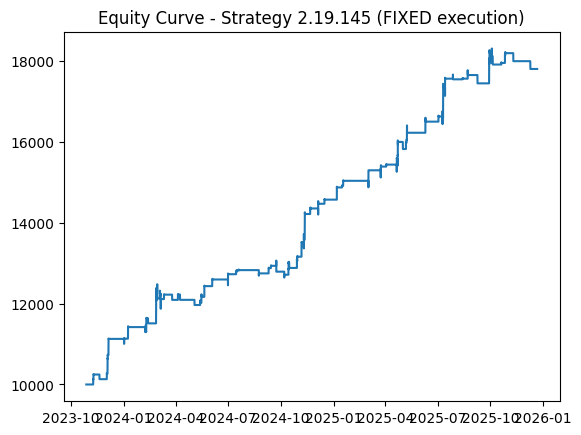

===== METRICS (FIX) =====
   Final Equity: 17800.4898
   Total Return: 0.7800
  CAGR (approx): 0.3072
   Max Drawdown: -0.0487
         Sharpe: 2.5834
         Trades: 122
        Winrate: 0.7131
  Avg PnL/Trade: 63.9384
  Profit Factor: 2.5583
Max DD: -0.04868145544228519


In [ ]:
equity_fix, trades_fix = backtest_strategy_2_19_145_FIXED(
    df_all,
    initial_equity=10_000,
    risk_percent=0.01,
    fee_rate=0.0004,
    slippage_bps=0.0,
    pip_size=0.1,
)

print("Trades:", len(trades_fix))
display(trades_fix.head(10))

plt.figure()
plt.plot(equity_fix.index, equity_fix.values)
plt.title("Equity Curve - Strategy 2.19.145 (FIXED execution)")
plt.show()
def compute_drawdown(equity: pd.Series) -> pd.Series:
    peak = equity.cummax()
    dd = equity / peak - 1.0
    return dd

def compute_metrics(
    equity: pd.Series,
    trades: pd.DataFrame,
    bars_per_year: int = 365*24,   # 1h bars
):
    equity = equity.dropna()
    rets = equity.pct_change().dropna()

    total_return = equity.iloc[-1] / equity.iloc[0] - 1.0

    dd = compute_drawdown(equity)
    max_dd = dd.min()

    # Sharpe annualized (rf=0)
    sharpe = np.nan
    if rets.std(ddof=0) > 0:
        sharpe = (rets.mean() / rets.std(ddof=0)) * np.sqrt(bars_per_year)

    n_trades = len(trades)
    winrate = (trades["pnl"] > 0).mean() if n_trades else np.nan

    # Profit factor
    if n_trades and (trades["pnl"] < 0).any():
        profit_factor = trades.loc[trades["pnl"] > 0, "pnl"].sum() / (-trades.loc[trades["pnl"] < 0, "pnl"].sum())
    else:
        profit_factor = np.nan

    avg_pnl = trades["pnl"].mean() if n_trades else np.nan
    expectancy = avg_pnl  # same here

    # CAGR approximation from bars
    years = len(equity) / bars_per_year
    cagr = (equity.iloc[-1] / equity.iloc[0])**(1/years) - 1 if years > 0 else np.nan

    return {
        "Final Equity": float(equity.iloc[-1]),
        "Total Return": float(total_return),
        "CAGR (approx)": float(cagr) if np.isfinite(cagr) else np.nan,
        "Max Drawdown": float(max_dd),
        "Sharpe": float(sharpe) if np.isfinite(sharpe) else np.nan,
        "Trades": int(n_trades),
        "Winrate": float(winrate) if np.isfinite(winrate) else np.nan,
        "Avg PnL/Trade": float(avg_pnl) if np.isfinite(avg_pnl) else np.nan,
        "Profit Factor": float(profit_factor) if np.isfinite(profit_factor) else np.nan,
    }

# ===== Run metrics =====
metrics_fix = compute_metrics(equity_fix, trades_fix, bars_per_year=365*24)

print("===== METRICS (FIX) =====")
for k, v in metrics_fix.items():
    if isinstance(v, float):
        print(f"{k:>15}: {v:.4f}")
    else:
        print(f"{k:>15}: {v}")

# Drawdown series if you want to plot
dd_fix = compute_drawdown(equity_fix)
print("Max DD:", dd_fix.min())



#### strat 3


===== METRICS (2.23.176) =====
Final Equity: 14784.2226
Total Return: 0.4784
Max Drawdown: -0.0519
      Sharpe: 2.0972
      Trades: 128
     Winrate: 0.6172


,entry_time,exit_time,side,entry,exit,qty,pnl,pnl_gross,fee,bars_held,reason
0,2023-11-07 20:00:00,2023-11-07 22:00:00,long,35494.293387,35383.000279,0.201081,-28.079724,-22.378901,5.700823,2,SL
1,2023-11-09 14:00:00,2023-11-09 16:00:00,long,37441.106766,37643.619870,0.153038,26.395833,30.992153,4.596319,2,SL
2,2023-11-15 18:00:00,2023-11-15 18:00:00,long,37165.028283,36483.224096,0.146645,-104.303220,-99.983161,4.320059,0,SL
3,2023-11-15 19:00:00,2023-11-15 21:00:00,long,37020.268755,37482.038199,0.147217,63.593174,67.980381,4.387207,2,SL
4,2023-11-19 23:00:00,2023-11-20 13:00:00,long,37253.574017,37069.887069,0.258063,-55.074753,-47.402713,7.672039,14,SL
5,2023-11-28 17:00:00,2023-11-28 21:00:00,long,37808.255752,38038.926510,0.195174,39.099573,45.020932,5.921359,4,SL
6,2023-12-02 19:00:00,2023-12-02 19:00:00,long,39246.573988,38888.967116,0.278004,-108.105121,-99.416309,8.688812,0,SL
7,2023-12-02 20:00:00,2023-12-02 22:00:00,long,39163.990088,39397.728440,0.279021,56.449675,65.217810,8.768134,2,SL
8,2023-12-04 00:00:00,2023-12-04 02:00:00,long,40141.453514,40557.748408,0.227962,87.540714,94.899241,7.358527,2,SL
9,2023-12-04 03:00:00,2023-12-04 05:00:00,long,40621.939274,41342.333433,0.185716,127.699960,133.788794,6.088834,2,TP


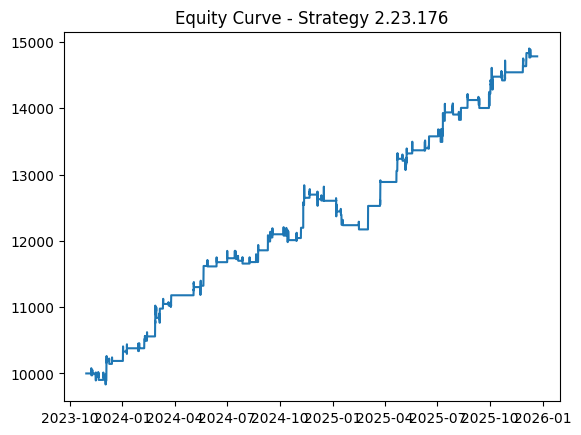

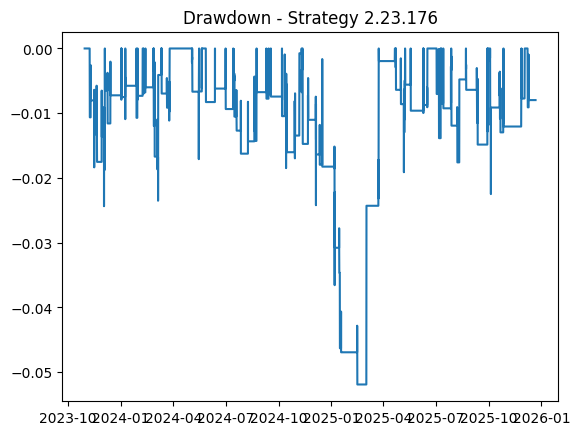

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------
# Indicators
# -------------------------
def true_range(df: pd.DataFrame) -> pd.Series:
    high = df["High"]
    low  = df["Low"]
    prev_close = df["Close"].shift(1)
    return pd.concat([
        (high - low),
        (high - prev_close).abs(),
        (low  - prev_close).abs()
    ], axis=1).max(axis=1)

def atr_wilder(df: pd.DataFrame, period: int) -> pd.Series:
    tr = true_range(df)
    return tr.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

def bollinger_bands(close: pd.Series, period: int, dev: float):
    ma = close.rolling(period).mean()
    sd = close.rolling(period).std(ddof=0)
    upper = ma + dev * sd
    lower = ma - dev * sd
    mid = ma
    return upper, mid, lower


# -------------------------
# Metrics
# -------------------------
def compute_drawdown(equity: pd.Series) -> pd.Series:
    peak = equity.cummax()
    return equity / peak - 1.0

def compute_metrics(equity: pd.Series, trades: pd.DataFrame, bars_per_year: int = 365*24):
    equity = equity.dropna()
    rets = equity.pct_change().dropna()

    total_return = equity.iloc[-1] / equity.iloc[0] - 1.0
    dd = compute_drawdown(equity)
    max_dd = dd.min()

    sharpe = np.nan
    if rets.std(ddof=0) > 0:
        sharpe = (rets.mean() / rets.std(ddof=0)) * np.sqrt(bars_per_year)

    n = len(trades)
    winrate = (trades["pnl"] > 0).mean() if n else np.nan

    return {
        "Final Equity": float(equity.iloc[-1]),
        "Total Return": float(total_return),
        "Max Drawdown": float(max_dd),
        "Sharpe": float(sharpe) if np.isfinite(sharpe) else np.nan,
        "Trades": int(n),
        "Winrate": float(winrate) if np.isfinite(winrate) else np.nan,
    }


# -------------------------
# Backtest: Strategy_2_23_176
# -------------------------
def backtest_strategy_2_23_176(
    df: pd.DataFrame,
    initial_equity: float = 10_000.0,
    risk_percent: float = 0.01,
    fee_rate: float = 0.0004,
    slippage_bps: float = 0.0,
    conservative_sl_tp_same_bar: bool = True,
):
    df = df.copy()

    # --- Params from java (đọc được) ---
    BBBarOpensPeriod = 10
    BBDev = 1.9
    PriceEntryMult = 1.8
    ExitAfterBars = 30
    ProfitTargetCoef = 3.6
    StopLossCoef = 2.6
    TrailingStopCoef = 1.5
    PeriodParam = 25
    Period2 = 14
    PendingExpireBars = 3

    # --- Indicators ---
    df["ATR20"]  = atr_wilder(df, 20)
    df["ATR25"]  = atr_wilder(df, 25)
    df["ATR200"] = atr_wilder(df, 200)

    upper, mid, lower = bollinger_bands(df["Close"], BBBarOpensPeriod, BBDev)
    df["BB_upper_s1"] = upper.shift(1)
    df["BB_lower_s1"] = lower.shift(1)

    # helper rolling
    df["HH_close_PP_s2"] = df["Close"].rolling(PeriodParam).max().shift(2)
    df["LL_close_PP_s2"] = df["Close"].rolling(PeriodParam).min().shift(2)

    df["HH_close_P2_s2"] = df["Close"].rolling(Period2).max().shift(2)
    df["LL_close_P2_s2"] = df["Close"].rolling(Period2).min().shift(2)

    # ATR shifts for distances
    df["ATR20_s1"]  = df["ATR20"].shift(1)
    df["ATR25_s1"]  = df["ATR25"].shift(1)
    df["ATR200_s1"] = df["ATR200"].shift(1)

    # fees & slippage
    def fee(notional: float) -> float:
        return fee_rate * notional

    def slip(price: float, is_buy: bool) -> float:
        s = slippage_bps / 10_000.0
        return price * (1 + s) if is_buy else price * (1 - s)

    # ---- ENTRY FORMULA (CẦN) ----
    # Vì file java bị cắt '...' ở dòng sqOpenOrder, mình để 1 hàm để bạn chỉnh đúng.
    def compute_entry_prices(row):
        """
        MẶC ĐỊNH (ước lượng hợp lý):
        - entry_long  = Highest(Close, PeriodParam, shift=2) + PriceEntryMult * ATR20(shift=1)
        - entry_short = Lowest (Close, PeriodParam, shift=2) - PriceEntryMult * ATR20(shift=1)

        Nếu bạn mở file java và thấy entry dùng Period2 hoặc dùng ATR khác,
        chỉ cần sửa đúng 2 dòng entry_long/entry_short ở đây.
        """
        hh = row["HH_close_PP_s2"]
        ll = row["LL_close_PP_s2"]
        atr_for_entry = row["ATR20_s1"]  # <-- có thể thay bằng ATR200_s1 hoặc thứ khác nếu java dùng

        if pd.isna(hh) or pd.isna(ll) or pd.isna(atr_for_entry):
            return None, None

        entry_long  = hh + PriceEntryMult * atr_for_entry
        entry_short = ll - PriceEntryMult * atr_for_entry
        return entry_long, entry_short

    equity = initial_equity
    equity_curve, equity_index = [], []
    trades = []

    pending = None
    pos = None

    start_i = max(250, PeriodParam + 50)  # đủ ATR200

    for i in range(start_i, len(df)):
        ts = df.index[i]
        row = df.iloc[i]
        o, h, l, c = row["Open"], row["High"], row["Low"], row["Close"]

        # (A) pending expiration
        if pending is not None and (i - pending["placed_i"] >= PendingExpireBars):
            pending = None

        # (B) fill pending
        if pos is None and pending is not None:
            if pending["side"] == "long" and h >= pending["entry"]:
                fill = slip(pending["entry"], is_buy=True)
                sl_dist = pending["sl_dist"]
                tp_dist = pending["tp_dist"]

                risk_amt = equity * risk_percent
                qty = risk_amt / sl_dist if sl_dist > 0 else 0.0

                if qty > 0:
                    pos = {
                        "side": "long",
                        "entry": fill,
                        "qty": qty,
                        "sl": fill - sl_dist,
                        "tp": fill + tp_dist,
                        "bars_held": 0,
                        "entry_time": ts,
                        "just_opened": True
                    }
                pending = None

            elif pending["side"] == "short" and l <= pending["entry"]:
                fill = slip(pending["entry"], is_buy=False)
                sl_dist = pending["sl_dist"]
                tp_dist = pending["tp_dist"]

                risk_amt = equity * risk_percent
                qty = risk_amt / sl_dist if sl_dist > 0 else 0.0

                if qty > 0:
                    pos = {
                        "side": "short",
                        "entry": fill,
                        "qty": qty,
                        "sl": fill + sl_dist,
                        "tp": fill - tp_dist,
                        "bars_held": 0,
                        "entry_time": ts,
                        "just_opened": True
                    }
                pending = None

        # (C) manage position SL/TP
        if pos is not None:
            side, entry, qty = pos["side"], pos["entry"], pos["qty"]
            sl, tp = pos["sl"], pos["tp"]

            exit_reason = None
            exit_price = None

            if side == "long":
                hit_sl = (l <= sl)
                hit_tp = (h >= tp)
                if hit_sl and hit_tp:
                    exit_reason, exit_price = ("SL&TP_same_bar -> SL", sl) if conservative_sl_tp_same_bar else ("SL&TP_same_bar -> TP", tp)
                elif hit_sl:
                    exit_reason, exit_price = "SL", sl
                elif hit_tp:
                    exit_reason, exit_price = "TP", tp
            else:
                hit_sl = (h >= sl)
                hit_tp = (l <= tp)
                if hit_sl and hit_tp:
                    exit_reason, exit_price = ("SL&TP_same_bar -> SL", sl) if conservative_sl_tp_same_bar else ("SL&TP_same_bar -> TP", tp)
                elif hit_sl:
                    exit_reason, exit_price = "SL", sl
                elif hit_tp:
                    exit_reason, exit_price = "TP", tp

            # (D) time exit
            if exit_reason is None:
                pos["bars_held"] += 1
                if pos["bars_held"] >= ExitAfterBars:
                    exit_reason, exit_price = "TimeExit", c

            if exit_reason is not None:
                if side == "long":
                    exit_eff = slip(exit_price, is_buy=False)
                    pnl_gross = qty * (exit_eff - entry)
                    fees = fee(entry * qty) + fee(exit_eff * qty)
                else:
                    exit_eff = slip(exit_price, is_buy=True)
                    pnl_gross = qty * (entry - exit_eff)
                    fees = fee(entry * qty) + fee(exit_eff * qty)

                pnl = pnl_gross - fees
                equity += pnl

                trades.append({
                    "entry_time": pos["entry_time"],
                    "exit_time": ts,
                    "side": side,
                    "entry": entry,
                    "exit": exit_eff,
                    "qty": qty,
                    "pnl": pnl,
                    "pnl_gross": pnl_gross,
                    "fee": fees,
                    "bars_held": pos["bars_held"],
                    "reason": exit_reason
                })
                pos = None

        # (E) trailing update for next bars (profit>=0)
        if pos is not None:
            trail_dist = TrailingStopCoef * row["ATR200_s1"]
            if pd.notna(trail_dist) and trail_dist > 0:
                if pos["side"] == "long" and c >= pos["entry"] and (not pos["just_opened"]):
                    pos["sl"] = max(pos["sl"], c - trail_dist)
                if pos["side"] == "short" and c <= pos["entry"] and (not pos["just_opened"]):
                    pos["sl"] = min(pos["sl"], c + trail_dist)
            pos["just_opened"] = False

        # Create pending (if flat & no pending)
        if pos is None and pending is None:
            bb_u = row["BB_upper_s1"]
            bb_l = row["BB_lower_s1"]

            long_signal  = pd.notna(bb_u) and (o < bb_u)
            short_signal = pd.notna(bb_l) and (o > bb_l) and (not long_signal)

            entry_long, entry_short = compute_entry_prices(row)

            atr20 = row["ATR20_s1"]
            atr25 = row["ATR25_s1"]

            if pd.notna(atr20) and pd.notna(atr25):
                sl_dist = StopLossCoef * atr20
                tp_dist = ProfitTargetCoef * atr25

                if sl_dist > 0 and tp_dist > 0:
                    if long_signal and entry_long is not None:
                        pending = {"side": "long", "entry": entry_long, "sl_dist": sl_dist, "tp_dist": tp_dist, "placed_i": i}
                    elif short_signal and entry_short is not None:
                        pending = {"side": "short", "entry": entry_short, "sl_dist": sl_dist, "tp_dist": tp_dist, "placed_i": i}

        # mark-to-market
        if pos is None:
            eq_mark = equity
        else:
            if pos["side"] == "long":
                eq_mark = equity + pos["qty"] * (c - pos["entry"])
            else:
                eq_mark = equity + pos["qty"] * (pos["entry"] - c)

        equity_curve.append(eq_mark)
        equity_index.append(ts)

    equity_curve = pd.Series(equity_curve, index=pd.DatetimeIndex(equity_index), name="equity")
    trades_df = pd.DataFrame(trades)
    return equity_curve, trades_df


# ===== RUN =====
equity_223, trades_223 = backtest_strategy_2_23_176(df_all)
metrics_223 = compute_metrics(equity_223, trades_223)

print("===== METRICS (2.23.176) =====")
for k, v in metrics_223.items():
    print(f"{k:>12}: {v:.4f}" if isinstance(v, float) else f"{k:>12}: {v}")

display(trades_223.head(10))

dd_223 = compute_drawdown(equity_223)

plt.figure()
plt.plot(equity_223.index, equity_223.values)
plt.title("Equity Curve - Strategy 2.23.176")
plt.show()

plt.figure()
plt.plot(dd_223.index, dd_223.values)
plt.title("Drawdown - Strategy 2.23.176")
plt.show()
